# Building the DESI DR1 absorber catalogue

This notebook explains, step by step, how the absorber catalogue is produced from the DESI DR1 quasar spectra,
using the functions of [`catalog_utils.py`](catalog_utils.py), and how to build your own
catalogue with them. The steps are run on 500 DESI DR1 spectra and shown one at a time.

The directory is self-contained: copy it anywhere and run the notebook from it.

| Path | What |
|---|---|
| `catalog_utils.py` | all the functions of the pipeline |
| `models/` | the fine-tuned continuum autoencoder ([Zenodo](https://doi.org/10.5281/zenodo.24500565)) and the U-Net ([Zenodo](https://doi.org/10.5281/zenodo.22711575), `UNet.h5`) |
| `data/rest_wave.h5` | the rest-frame wavelength grid of the networks |
| `data/filtered_ion_lams.pkl` | the transitions $\texttt{PILOT}$ can assign |
| `data/desi_dr1_subsample500.h5` | 500 DESI DR1 quasar spectra, drawn at random (seed 2025) from the 129 601 of the parent sample; an example of the input format |

**Pipeline, per spectrum**

| Step | What | Function |
|---|---|---|
| 0 | Input spectra: quasars resampled to the QSO rest frame | `read_spectra` |
| 1 | Continuum with the fine-tuned autoencoder | `predict_continuum` |
| 2 | Absorption pixels with the U-Net on $F/C$ | `normalize`, `detect_lines` |
| 3 | Continuum error vs spectrum S/N | `calculate_snr`, `cont_frac_err_vs_snr` |
| 4 | Regions → EW, $\mathrm{S/N}_\mathrm{line}$, ion and transition ($\texttt{PILOT}$) | `classify_absorbers` |

**Outputs** (`build_catalog`): a spectra file with the continuum and U-Net labels, and the
catalogue with one row per detected region (`pred_df`) plus one row per spectrum (`spectra`).

**Requirements**: Python 3.11 with numpy, scipy, pandas (+ PyTables), h5py, astropy,
linetools, tqdm, matplotlib, and TensorFlow 2.19 / Keras 3 (see `requirements.txt`). A GPU
makes the network steps fast but is not needed for 500 spectra.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import catalog_utils as cu       # in this directory

ion_colors = pd.read_pickle(cu.PATHS["ion_colors"])
for k, v in cu.PATHS.items():
    print(f"{k:14s} {v}")

wavelength     /data/fpistis/DESI/catalog_pipeline/data/rest_wave.h5
autoencoder    /data/fpistis/DESI/catalog_pipeline/models/autoencoder_finetuned_nmf.h5
unet           /data/fpistis/DESI/catalog_pipeline/models/best_unet_nonoise_snr0_longrun.h5
ion_lams       /data/fpistis/DESI/catalog_pipeline/data/filtered_ion_lams.pkl
ion_colors     /data/fpistis/DESI/catalog_pipeline/data/ion_color_map.pkl
subsample      /data/fpistis/DESI/catalog_pipeline/data/desi_dr1_subsample500.h5


## Step 0 — the input spectra

The production input (the parent sample, 129 601 spectra) was made by two upstream scripts
of the analysis:

* `desi_dataprocessing.py`: DESI DR1 quasar coadds, non-BAL (BAL catalogue), $r < 21$,
  $2.5 < z < 4$; each spectrum is moved to the QSO rest frame and linearly resampled onto a
  common grid, with the inverse variance propagated through the resampling
  (so that $\sqrt{\sum \sigma_i^2}\,\Delta\lambda$ is the correct EW error on
  the new grid). Each spectrum is normalized by `norm`, its median flux in 1425–1475 Å.
* `desi_catalog.py`: duplicate TARGETIDs removed, grid cut to $\lambda \geq 1230$ Å
  (redwards of Ly&alpha;; 16384 pixels up to 3095 Å, $\Delta\lambda \simeq 0.114$ Å), spectra
  with $\mathrm{S/N} > 0$ kept.

`data/desi_dr1_subsample500.h5` holds 500 of these spectra, in the format `read_spectra`
reads (an HDF5 file, $n$ spectra on the grid of `data/rest_wave.h5`):

| Dataset | Shape | What |
|---|---|---|
| `ids` | $(n,)$ | identifier (DESI TARGETID); the `ID` of the catalogue |
| `zqso` | $(n,)$ | quasar redshift |
| `norm` | $(n,)$ | median flux in 1425–1475 Å (rest frame) |
| `flux`, `ivar` | $(n, 16384)$ | flux and inverse variance |
| `nan_mask` | $(n, 16384)$ | True on pixels outside the observed range or bad |
| `rest_wave` | $(16384,)$ | the grid (optional) |

To make a catalogue of other spectra, write them in this format (see the last section).

In [2]:
SUB = cu.PATHS["subsample"]                  # the 500 spectra of this notebook
wavelength = cu.load_wavelength()
ion_lams = cu.load_ion_lams()
print(f"{cu.n_parent_spectra(SUB)} spectra, {wavelength.size} pixels, "
      f"{wavelength[0]:.1f}-{wavelength[-1]:.1f} A, step {np.diff(wavelength)[0]:.4f} A")

# transitions PILOT can assign (those of the training mocks)
pd.DataFrame([(ion, ", ".join(f"{q.value:.2f}" for q in lams)) for ion, lams in ion_lams.items()],
             columns=["ion", "rest wavelengths [A]"])

500 spectra, 16384 pixels, 1230.0-3094.9 A, step 0.1138 A


,ion,rest wavelengths [A]
0,AlII,1670.79
1,CII,1334.53
2,CIV,"1548.20, 1550.78"
3,FeII,"2382.77, 2600.17, 1608.45"
4,MgII,"2796.35, 2803.53"
5,MnII,"2576.88, 2594.50"
6,NiII,"1741.55, 1709.60"
7,OI,1302.17
8,SII,"1259.52, 1253.81, 1250.58"
9,SiII,"1260.42, 1526.71, 1304.37, 1808.01"


In [3]:
N_DEMO = cu.n_parent_spectra(SUB)            # all the spectra of the subsample
rows = np.arange(N_DEMO)
d = cu.read_spectra(rows, SUB)
snr = cu.calculate_snr(d["flux"], d["ivar"])
print({k: v.shape for k, v in d.items()})
print(f"spectrum S/N (median per pixel): median {np.median(snr):.2f}, range {snr.min():.2f}-{snr.max():.2f}; "
      f"z_QSO {d['zqso'].min():.2f}-{d['zqso'].max():.2f}")

{'ids': (500,), 'zqso': (500,), 'norm': (500,), 'flux': (500, 16384), 'ivar': (500, 16384), 'nan_mask': (500, 16384)}
spectrum S/N (median per pixel): median 1.96, range 0.14-27.96; z_QSO 2.60-3.91


## Step 1 — continuum

The continuum is predicted by a dense autoencoder pre-trained on mock spectra and fine-tuned
on well-fitted NMF continua of DESI quasars (`finetune_autoencoder_nmf.py`). Its input is
`flux / norm` with 0 on masked pixels; its output (`cont_scaled`, continuum / norm) is
multiplied back by `norm` and smoothed with a 10-pixel running median.

`load_models` also sets TensorFlow as in the production run (TF32 off: TF32 matmuls change
the continuum by up to ~1% per pixel and from run to run).

2026-10-15 12:34:13.004113: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-15 12:34:13.018501: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792060453.033243  944838 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792060453.037950  944838 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792060453.050523  944838 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

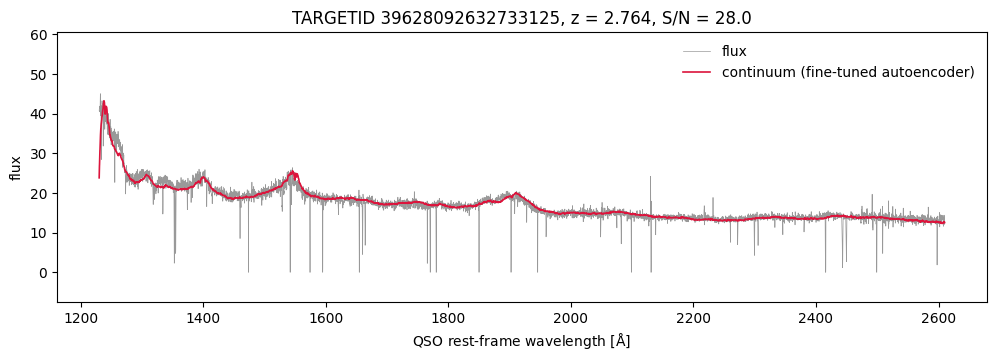

In [4]:
autoencoder, unet = cu.load_models()
cont_scaled, continuum = cu.predict_continuum(autoencoder, d["flux"], d["norm"], d["nan_mask"])

k = int(np.argmax(snr))     # the highest-S/N spectrum of the subsample (also in Step 2)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(wavelength, d["flux"][k], color="0.6", lw=0.5, label="flux")
ax.plot(wavelength, continuum[k], color="crimson", lw=1.2, label="continuum (fine-tuned autoencoder)")
ax.set(xlabel=r"QSO rest-frame wavelength [$\mathrm{\AA}$]", ylabel="flux",
       title=f"TARGETID {d['ids'][k]}, z = {d['zqso'][k]:.3f}, S/N = {snr[k]:.1f}")
ax.set_ylim(np.nanpercentile(d["flux"][k], 0.5) - 0.2 * np.nanmax(continuum[k]), 1.4 * np.nanmax(continuum[k]))
ax.legend(frameon=False);

## Step 2 — absorption pixels

The flux and its error are divided by the continuum, $F/C$ and $\sigma/C$
(`normalize`), and the U-Net labels every pixel of $F/C$ as continuum (0) or absorption (1)
(`detect_lines`). A contiguous run of absorption pixels is one **region**, the unit of the
catalogue.

The figure zooms on four of the most significant regions of the spectrum of Step 1, the
highest-S/N one of the subsample: the U-Net marks each absorption line, here mostly the two members of doublets, as a
separate region; the continuum ($F/C = 1$, dashed) sets the zero of the absorption.

regions per spectrum: median 132, total 65626 in 500 spectra


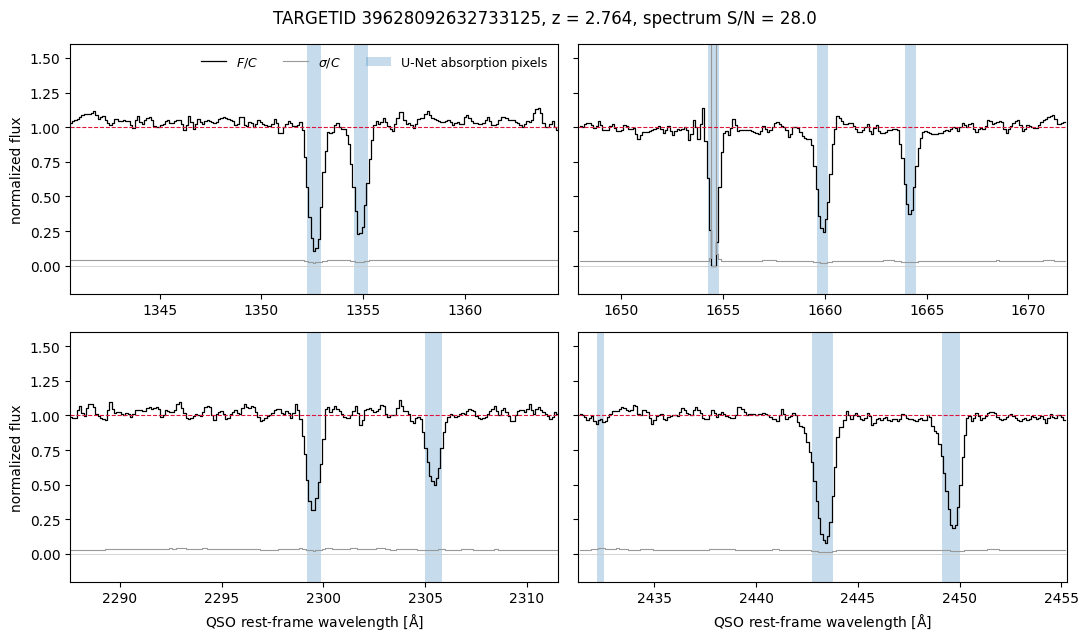

In [5]:
flux_n, noise_n = cu.normalize(d["flux"], d["ivar"], continuum, d["nan_mask"])
labels = cu.detect_lines(unet, flux_n, d["nan_mask"])

n_regions = [len(cu.find_predicted_regions(labels[i][np.isfinite(labels[i])] > 0.5)) for i in range(N_DEMO)]
print(f"regions per spectrum: median {np.median(n_regions):.0f}, total {sum(n_regions)} in {N_DEMO} spectra")

# zoom-in on example absorptions: the four most significant regions (rough EW = sum(1 - F/C) dlambda
# over its error) of spectrum k (Step 1), at least 40 A apart
regs = []
for s0, s1 in cu.find_predicted_regions(labels[k] == 1):
    sl = slice(s0, s1 + 1)
    regs.append((np.nansum(1 - flux_n[k, sl]) / np.sqrt(np.nansum(noise_n[k, sl] ** 2)), s0, s1))
zooms = []
for sig, s0, s1 in sorted(regs, reverse=True):
    lam0 = 0.5 * (wavelength[s0] + wavelength[s1])
    if all(abs(lam0 - z[0]) > 40 for z in zooms):
        zooms.append((lam0, s0, s1, sig))
    if len(zooms) == 4:
        break
zooms.sort()

HALF = 12      # A, half width of the zoom windows
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharey=True)
for az, (lam0, s0, s1, sig) in zip(axes.flat, zooms):
    w = np.abs(wavelength - lam0) <= HALF
    az.step(wavelength[w], flux_n[k, w], where="mid", color="k", lw=0.9, label=r"$F/C$")
    az.step(wavelength[w], noise_n[k, w], where="mid", color="0.6", lw=0.8, label=r"$\sigma/C$")
    az.fill_between(wavelength[w], -0.2, 1.6, where=labels[k, w] == 1, step="mid", color="tab:blue",
                    alpha=0.25, lw=0, label="U-Net absorption pixels")
    az.axhline(1, color="crimson", lw=0.8, ls="--")
    az.axhline(0, color="0.8", lw=0.6)
    az.set(xlim=(lam0 - HALF, lam0 + HALF), ylim=(-0.2, 1.6))
for az in axes[1]:
    az.set_xlabel(r"QSO rest-frame wavelength [$\mathrm{\AA}$]")
for az in axes[:, 0]:
    az.set_ylabel("normalized flux")
axes[0, 0].legend(frameon=False, fontsize=9, loc="upper right", ncol=3)
fig.suptitle(f"TARGETID {d['ids'][k]}, z = {d['zqso'][k]:.3f}, spectrum S/N = {snr[k]:.1f}")
fig.tight_layout()

## Step 3 — continuum error

The continuum is not known exactly, so the EW error of each region includes a continuum term.
A misplaced continuum shifts all the pixels of a region coherently, so it is modelled as a
fractional offset $\epsilon$ of the continuum level:

$$
\begin{aligned}
\Delta \mathrm{EW}_\mathrm{stat} &= \Delta\lambda \sqrt{\sum_i \sigma_i^2 / C_i^2}, \\
\Delta \mathrm{EW}_\mathrm{cont} &= \epsilon\,\Delta\lambda \sum_i \max(F_i/C_i,\, 0), \\
\Delta \mathrm{EW} &= \sqrt{\Delta \mathrm{EW}_\mathrm{stat}^2 + \Delta \mathrm{EW}_\mathrm{cont}^2}.
\end{aligned}
$$

$\epsilon$ depends on the spectrum S/N: it was measured by degrading high-S/N spectra and
taking the scatter of the predicted continuum level ($1.4826\times\mathrm{MAD}$ of
$\mathrm{median}(C/C_\mathrm{ref}) - 1$, `degradation_test.py`). `cont_frac_err_vs_snr`
interpolates that table in $\log(\mathrm{S/N})$, constant beyond it.

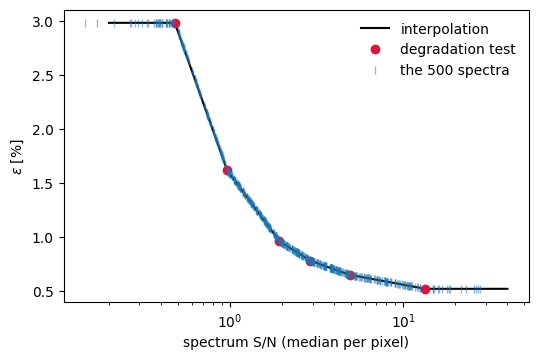

In [6]:
cfe = cu.cont_frac_err_vs_snr(snr)
s = np.geomspace(0.2, 40, 200)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(s, 100 * cu.cont_frac_err_vs_snr(s), color="k", label="interpolation")
ax.plot(cu.CONT_ERR_SNR, 100 * cu.CONT_ERR, "o", color="crimson", label="degradation test")
ax.plot(snr, 100 * cfe, "|", color="tab:blue", alpha=0.5, label=f"the {N_DEMO} spectra")
ax.set(xscale="log", xlabel="spectrum S/N (median per pixel)", ylabel=r"$\epsilon$ [%]")
ax.legend(frameon=False);

## Step 4 — measurement and classification of the regions

The regions are classified by $\texttt{PILOT}$ (Physically-Informed Line identificatiOn Tool):
`classify_absorbers` runs `enforce_transition_strength_ew_ordering` on each spectrum:

1. **Measurement** of every region: centroid (inverse-variance and depth weighted), EW,
   $\Delta\mathrm{EW}$ (Step 3) and $\mathrm{S/N}_\mathrm{line} = \mathrm{EW}/\Delta\mathrm{EW}$.
2. **Classification** by redshift coincidence: each region is tested as every transition of
   `ion_lams`; transitions of the same ion whose redshifts agree within the velocity
   tolerance `v_tol` (a parameter of `classify_absorbers` and `build_catalog`; 250 km/s in the
   production catalogue, `cu.V_TOL`) make a system, scored by the redshift match and by the
   fraction of the ion's transitions found.
3. **Curve-of-growth constraints**: for two transitions of the same ion, the one with the
   larger $f\lambda$ must have the larger EW, and their ratio cannot exceed the optically thin
   one; a match is rejected only when it violates these by more than `EW_SIGMA_MARGIN` = 3
   standard deviations. In these tests the continuum error is fully correlated between the two
   regions (the same continuum offset affects both lines of a doublet), so it largely cancels.
4. **Output**: one row per region; EW and $\Delta\mathrm{EW}$ are converted to the absorber rest
   frame, $W_r = W_\mathrm{QSO}(1+z_\mathrm{QSO})/(1+z_\mathrm{abs})$, for classified regions.

This step runs on the CPU and takes ~0.1 s per spectrum (about a minute for the subsample).

In [7]:
V_TOL = 250.0                    # km/s, velocity tolerance of the line associations (production value)
pred = cu.classify_absorbers(d["ids"], flux_n, noise_n, wavelength, d["zqso"], labels, ion_lams, cfe,
                             v_tol=V_TOL)
print(f"{len(pred)} regions, {pred['ion_pred'].notna().mean():.1%} classified")
pd.DataFrame(cu.CATALOG_COLUMNS.items(), columns=["column", "meaning"])

/data/fpistis/envs/quasars/lib/python3.11/site-packages/linetools/lists/linelist.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename
        Use numpy.iterable() instead. [linetools.abund.solar]
        Use numpy.iterable() instead.


read_sets: Using set file -- 
  /data/fpistis/envs/quasars/lib/python3.11/site-packages/linetools/lists/sets/llist_v1.3.ascii
Loading abundances from Asplund2009
Abundances are relative by number on a logarithmic scale with H=12


Processing spectra:   0%|          | 0/500 [00:00<?, ?it/s]/data/fpistis/envs/quasars/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/data/fpistis/DESI/catalog_pipeline/catalog_utils.py:1006: RuntimeWarning: All-NaN slice encountered
  best_score_i = np.nanmax(score, axis=1)
/data/fpistis/DESI/catalog_pipeline/catalog_utils.py:1010: RuntimeWarning: All-NaN slice encountered
  best_score_j = np.nanmax(score, axis=0)
/data/fpistis/DESI/catalog_pipeline/catalog_utils.py:1051: RuntimeWarning: All-NaN slice encountered
  min_dz = np.nanmin(dz, axis=1)
Processing spectra: 100%|██████████| 500/500 [00:51<00:00,  9.64it/s]


65626 regions, 65.5% classified


,column,meaning
0,ID,DESI TARGETID of the spectrum
1,zqso,quasar redshift
2,lam,observed-frame centroid of the region [A]
3,"start, end",first / last pixel of the region on the rest-f...
4,"lam05, lam95",observed-frame wavelength of the region edges [A]
5,"ion_pred, wl_pred",classified ion and floor(rest wavelength) of t...
6,zabs,absorber redshift of the classified transition
7,score,redshift-match x completeness score of the cla...
8,SNR_line,EW / dEW
9,"EW, dEW","equivalent width and its error, absorber rest ..."


In [8]:
pred.head(8)

,ID,zqso,lam,start,end,lam05,lam95,ion_pred,wl_pred,zabs,score,SNR_line,EW,dEW,dEW_stat,dEW_cont,EW_qso,dEW_qso
0,2780987670921220,2.708737,4565.323223,6,10,4564.279388,4565.968059,SiII,1304.0,2.500021,0.973905,5.077777,0.350452,0.069017,0.068991,0.001885,0.330730,0.065133
1,2780987670921220,2.708737,4589.060750,60,68,4587.076440,4590.453781,SiII,1260.0,2.640892,0.797817,6.222715,0.440347,0.070764,0.070636,0.004262,0.432291,0.069470
2,2780987670921220,2.708737,4593.408954,75,75,4593.408954,4593.408954,SII,1250.0,2.673029,0.166210,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
3,2780987670921220,2.708737,4600.116870,85,96,4597.630631,4602.274474,MgII,2796.0,0.645041,0.415398,5.235384,0.860410,0.164345,0.163639,0.015220,0.381642,0.072897
4,2780987670921220,2.708737,4611.528078,116,120,4610.717827,4612.406497,SiII,1260.0,2.658717,0.890275,2.768857,0.146893,0.053052,0.052970,0.002938,0.144912,0.052336
5,2780987670921220,2.708737,4616.838994,130,131,4616.628174,4617.050341,FeII,2382.0,0.937597,0.144504,1.486603,0.109923,0.073943,0.073909,0.002225,0.057428,0.038631
6,2780987670921220,2.708737,4655.002343,219,223,4654.201092,4655.889762,FeII,1608.0,1.894090,0.259633,2.164035,0.219850,0.101593,0.101532,0.003508,0.171559,0.079277
7,2780987670921220,2.708737,4671.499160,256,264,4669.821294,4673.198635,CII,1334.0,2.500477,0.479809,8.692420,0.903431,0.103933,0.103918,0.001777,0.852699,0.098097


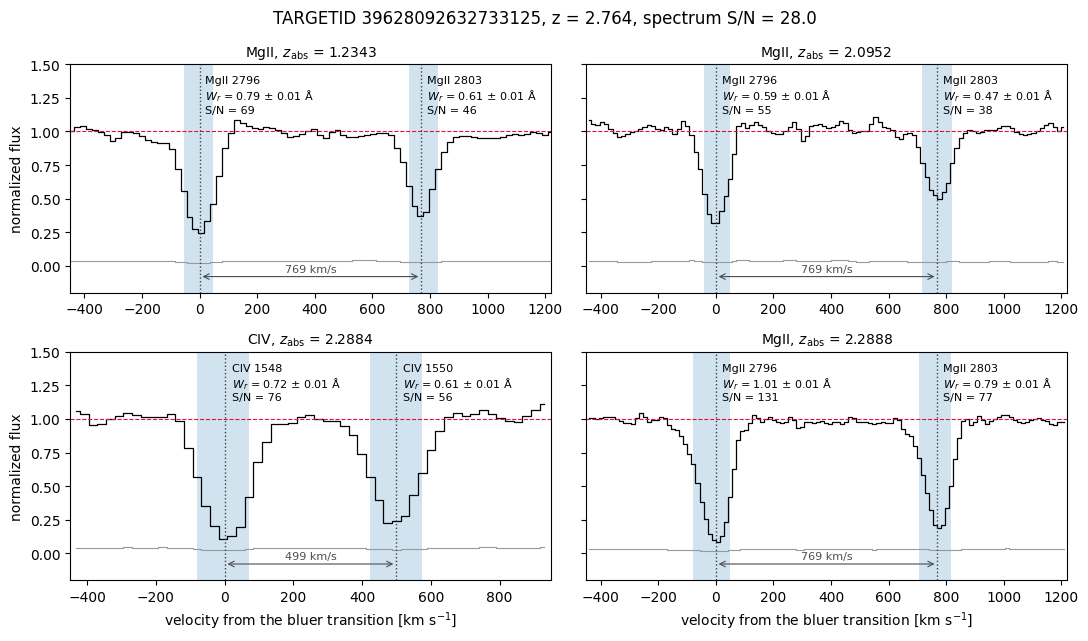

In [9]:
# the classified doublets of spectrum k (Steps 1-2) in velocity space: both members classified as the same
# ion, redshifts within the tolerance; the four most significant (weaker member's S/N_line). Both members
# in one panel, velocity relative to the bluer transition at the mean z_abs of the pair: the redder member
# must sit at the doublet separation dv = c (lambda_2 / lambda_1 - 1) (dotted lines: expected positions)
DOUBLETS = {"CIV": (1548, 1550), "SiIV": (1393, 1402), "MgII": (2796, 2803)}
pk = pred[(pred.ID == d["ids"][k]) & pred.ion_pred.isin(list(DOUBLETS))]
dbl = []
for ion, (w1, w2) in DOUBLETS.items():
    a, b = pk[(pk.ion_pred == ion) & (pk.wl_pred == w1)], pk[(pk.ion_pred == ion) & (pk.wl_pred == w2)]
    for _, r1 in a.iterrows():
        dz = (b.zabs - r1.zabs).abs()
        if len(b) and dz.min() <= V_TOL / cu.C_KMS * (1 + r1.zabs):
            r2 = b.loc[dz.idxmin()]
            dbl.append((min(r1.SNR_line, r2.SNR_line), ion, r1, r2))
dbl = sorted(dbl, key=lambda t: -t[0])[:4]
dbl.sort(key=lambda t: t[2].zabs)

PAD = 450                                            # km/s beyond the two lines
lam_obs = wavelength * (1 + d["zqso"][k])            # observed frame
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharey=True)
for ax, (_, ion, r1, r2) in zip(axes.flat, dbl):
    zabs = 0.5 * (r1.zabs + r2.zabs)
    lam1, lam2 = (next(q.value for q in ion_lams[ion] if int(q.value) == int(r.wl_pred)) for r in (r1, r2))
    dv = cu.C_KMS * (lam2 / lam1 - 1)                # doublet separation [km/s]
    v = cu.C_KMS * (lam_obs / (lam1 * (1 + zabs)) - 1)
    w = (v >= -PAD) & (v <= dv + PAD)
    ax.step(v[w], flux_n[k, w], where="mid", color="k", lw=0.9, label=r"$F/C$")
    ax.step(v[w], noise_n[k, w], where="mid", color="0.6", lw=0.8, label=r"$\sigma/C$")
    ax.fill_between(v[w], -0.2, 1.6, where=labels[k, w] == 1, step="mid", color="tab:blue",
                    alpha=0.2, lw=0, label="U-Net absorption pixels")
    ax.axhline(1, color="crimson", lw=0.8, ls="--")
    for r, x in ((r1, 0.0), (r2, dv)):
        ax.axvline(x, color="0.25", lw=1, ls=":")
        ax.text(x + 20, 1.42, f"{ion} {int(r.wl_pred)}\n$W_r$ = {r.EW:.2f} ± {r.dEW:.2f} $\\mathrm{{\\AA}}$\n"
                f"S/N = {r.SNR_line:.0f}", ha="left", va="top", fontsize=8)
    ax.annotate("", xy=(dv, -0.08), xytext=(0, -0.08), arrowprops=dict(arrowstyle="<->", color="0.3", lw=0.8))
    ax.text(0.5 * dv, -0.06, f"{dv:.0f} km/s", ha="center", va="bottom", fontsize=8, color="0.3")
    ax.set(xlim=(-PAD, dv + PAD), ylim=(-0.2, 1.5))
    ax.set_title(f"{ion}, $z_\\mathrm{{abs}}$ = {zabs:.4f}", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel(r"velocity from the bluer transition [km s$^{-1}$]")
for ax in axes[:, 0]:
    ax.set_ylabel("normalized flux")
for ax in axes.flat[len(dbl):]:
    ax.set_visible(False)
fig.suptitle(f"TARGETID {d['ids'][k]}, z = {d['zqso'][k]:.3f}, spectrum S/N = {snr[k]:.1f}")
fig.tight_layout()

## Make your own catalogue

`build_catalog` runs Steps 1–4 over all the spectra of an input file (`parent`, in the
format of Step 0) in chunks of `CHUNK` spectra and writes the two output files:

* `spectra_out`: `continuum`, `continuum_scaled` and `labels_pred` $(n, 16384)$, plus links to
  the datasets of the input file;
* `catalog_out`: the catalogue, `pred_df` (one row per region, columns above) and `spectra`
  (TARGETID, S/N and continuum error of each spectrum), read with `pd.read_hdf(path, key)`.

`n_max` limits the run to the first spectra (tests); `cont_frac_err` replaces the
S/N-dependent continuum error by a constant; `v_tol` (km/s) and `ew_sigma_margin` set
$\texttt{PILOT}$ (Step 4) and are stored as attributes of both outputs. The production catalogue (129 601 spectra) took
≈1.5 h on one A2 GPU, mostly the classification; it is made by the same steps.

Below, the catalogue of the 500 spectra (about a minute) and its summary (`summarize`): the
share of the continuum term in $\Delta\mathrm{EW}$, and the most frequent ions.

In [10]:
import os
os.makedirs("output", exist_ok=True)
pred_df, spectra = cu.build_catalog(
    spectra_out="output/desi_dr1_subsample500_continuum_labels.h5",
    catalog_out="output/desi_dr1_subsample500_catalog.h5",
    parent=SUB,              # your own spectra file here
    v_tol=V_TOL,             # km/s, PILOT velocity tolerance
)
with pd.HDFStore("output/desi_dr1_subsample500_catalog.h5", "r") as store:
    print("PILOT settings stored:", {k: getattr(store.get_storer("pred_df").attrs, k)
                                         for k in ("v_tol", "ew_sigma_margin")})

        Use numpy.iterable() instead. [linetools.abund.solar]
        Use numpy.iterable() instead.


Loading abundances from Asplund2009
Abundances are relative by number on a logarithmic scale with H=12


Processing spectra:   0%|          | 0/500 [00:00<?, ?it/s]/data/fpistis/envs/quasars/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1241: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/data/fpistis/DESI/catalog_pipeline/catalog_utils.py:1006: RuntimeWarning: All-NaN slice encountered
  best_score_i = np.nanmax(score, axis=1)
/data/fpistis/DESI/catalog_pipeline/catalog_utils.py:1010: RuntimeWarning: All-NaN slice encountered
  best_score_j = np.nanmax(score, axis=0)
/data/fpistis/DESI/catalog_pipeline/catalog_utils.py:1051: RuntimeWarning: All-NaN slice encountered
  min_dz = np.nanmin(dz, axis=1)
Processing spectra: 100%|██████████| 500/500 [00:52<00:00,  9.60it/s]


spectra 0-500 of 500: 65626 regions (57 s)
65626 regions in 500 spectra; classified 65.5%
dEW_cont / dEW_stat: median 0.03 (16-84%: 0.01-0.06), > 1 for 0.0% of the regions
ion_pred
MgII    12544
FeII     9763
MnII     8902
CIV      3415
SiII     3007
NiII     2786
SiIV     1269
SII       487
ZnII      353
AlII      263
Catalogue saved to output/desi_dr1_subsample500_catalog.h5 (65626 regions, 60 s)
classifier settings stored: {'v_tol': np.float64(250.0), 'ew_sigma_margin': np.float64(3.0)}


/data/fpistis/DESI/catalog_pipeline/catalog_utils.py:435: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block3_values] [items->Index(['ion_pred'], dtype='object')]

  pred_df.to_hdf(catalog_out, key="pred_df", mode="w")
